# Imports

In [55]:
import numpy as np
import matplotlib
matplotlib.rc_file('C:\\Users\\runner\\matplotlibrc.txt')
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import pandas as pd
from tqdm import tqdm
import subprocess

import os, sys
sys.path.append("D:\\DATA\\ActivePIC")
from pathlib import Path

rsoft_python_paths = [
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\most\python",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\bin",
    r"C:\Synopsys\PhotonicSolutions\2024.09-SP2-3\RSoft\products\python\python3.11\Lib\site-packages"
]
for p in rsoft_python_paths:
    if p not in sys.path:
        sys.path.insert(0, p)
from rstools import RSoftCircuit

import importlib
import rsoft_lib
import rsoft_lib.geometry as geom
importlib.reload(geom)
importlib.reload(rsoft_lib)

print(hasattr(geom, 'save_gds2'))
print(hasattr(rsoft_lib, 'save_gds2'))

import rsoft_lib as rlib
print(rlib.__file__)
print(hasattr(rlib, 'save_gds2'))
print(dir(rlib))

import rsoft_lib.geometry as geom

print(geom.__file__)
print(hasattr(geom, 'save_gds2'))
print(dir(geom))

import importlib

True
True
D:\DATA\ActivePIC\rsoft_lib\__init__.py
True
['BEND_LOSS_CSV', 'BEND_MODE_DIR', 'BEND_MODE_ROOT', 'FieldData', 'MODE_LIB_DIR', 'MonitorData', 'RSoftCircuit', '__all__', '__builtins__', '__cached__', '__doc__', '__file__', '__loader__', '__name__', '__package__', '__path__', '__spec__', '_env', 'add_fields', 'bend_curvature', 'bend_modes', 'best_offset', 'build_bend_loss_table', 'classify_modes', 'edge_to_peak_ratio', 'euler_ramp_length', 'euler_sbend', 'euler_sbend_fixed_ramp', 'euler_sbend_from_ramp', 'ex_mode_index', 'export_symbols', 'fields', 'find_material_file', 'geometry', 'get_loss', 'junction_offset', 'load_loss_table', 'loss_dB_per_cm_from_neff_imag', 'material_nk', 'materials', 'mirror_x', 'mode_field', 'modes', 'monitors', 'n_clad', 'parallel_path', 'param_str', 'read_all_symbols', 'read_fld', 'read_mode', 'read_monitor', 'read_nk', 'read_straight_mode', 'read_symbol', 'read_te_mode', 'regrid', 'run_sim', 'save_gds', 'save_gds2', 'sbend_lengths', 'sbend_loss', 'si

# Draw Euler bends

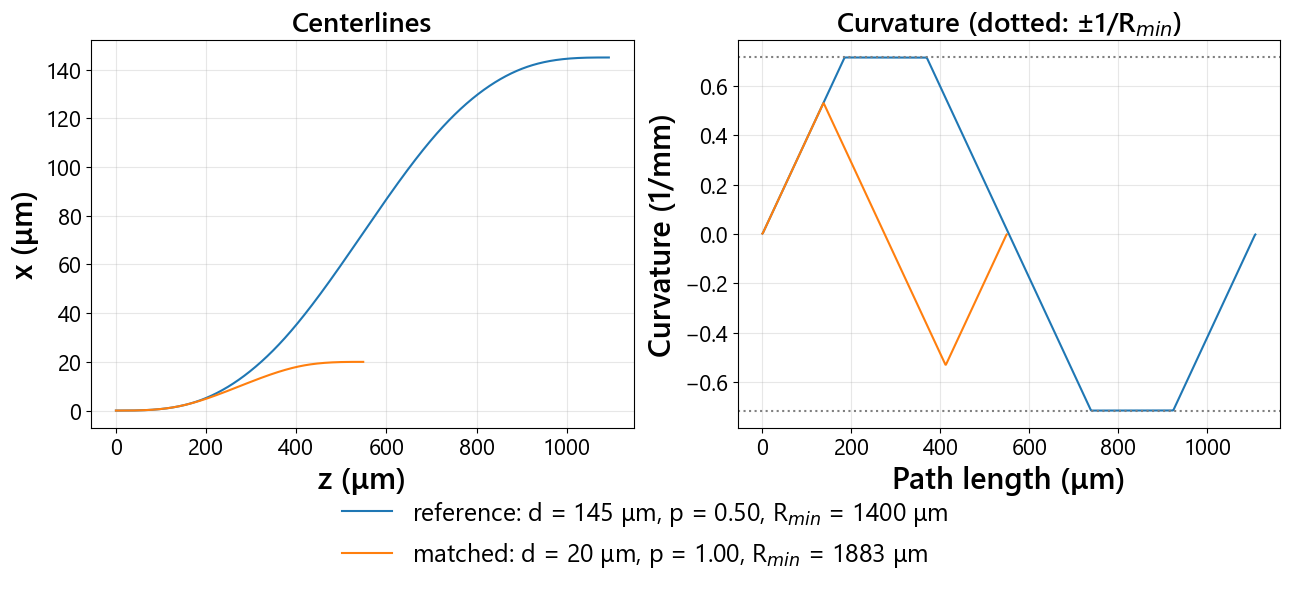

saved D:\DATA\NullingPIC_Gen2_sims\Euler_bends\EulerBend_d145p000_Rmin1400p000_p0p500_w3p400.gds
saved D:\DATA\NullingPIC_Gen2_sims\Euler_bends\EulerBend_d20p000_Rmin1882p957_p1p000_w3p400_matchedTo_d145p000_Rmin1400p000_p0p500.gds


In [3]:
R_min, p, d_ref = 1400.0, 0.5, 145.0    # reference Euler bend
d_new = 20.0                            # offset of the bend to match

x_ref, z_ref, phi_ref = rlib.euler_sbend(d_ref, R_min, p)
x_new, z_new, phi_new, par = rlib.euler_sbend_fixed_ramp(d_new, d_ref, R_min, p, return_params=True)   # warns if the peak curvature must be lower

s_ref, k_ref = rlib.bend_curvature(x_ref, z_ref, phi_ref)
s_new, k_new = rlib.bend_curvature(x_new, z_new, phi_new)
label_ref = f"reference: d = {d_ref:g} μm, p = {p:.2f}, R$_{{min}}$ = {R_min:.0f} μm"
label_new = f"matched: d = {d_new:g} μm, p = {par['p']:.2f}, R$_{{min}}$ = {par['R_min']:.0f} μm"

fig, ax = plt.subplots(1, 2, figsize=(13, 6))

ax[0].plot(z_ref, x_ref, label=label_ref)
ax[0].plot(z_new, x_new, label=label_new)
ax[0].set_xlabel("z (μm)")
ax[0].set_ylabel("x (μm)")
ax[0].set_title("Centerlines")
ax[0].grid(alpha=0.3)

ax[1].plot(s_ref, k_ref * 1e3)
ax[1].plot(s_new, k_new * 1e3)
ax[1].axhline(1e3 / R_min, linestyle="dotted", color="gray")
ax[1].axhline(-1e3 / R_min, linestyle="dotted", color="gray")
ax[1].set_xlabel("Path length (μm)")
ax[1].set_ylabel("Curvature (1/mm)")
ax[1].set_title("Curvature (dotted: ±1/R$_{min}$)")
ax[1].grid(alpha=0.3)

# One legend for both panels, centered below them
handles, labels = ax[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=1, frameon=False)
fig.tight_layout(rect=(0, 0.14, 1, 1))
plt.show()

out_dir = r"D:\DATA\NullingPIC_Gen2_sims\Euler_bends"
os.makedirs(out_dir, exist_ok=True)
width = 3.4                      # waveguide width of the GDS outline (um)
save_csv = True                  # also save the centerline (s, x, z, angle, curvature) next to each GDS file

ps = rlib.param_str
name_ref = f"EulerBend_d{ps(d_ref)}_Rmin{ps(R_min)}_p{ps(p)}_w{ps(width)}"
name_new = (f"EulerBend_d{ps(d_new)}_Rmin{ps(par['R_min'])}_p{ps(par['p'])}_w{ps(width)}"
            f"_matchedTo_d{ps(d_ref)}_Rmin{ps(R_min)}_p{ps(p)}")

bends = [(name_ref, (x_ref, z_ref, phi_ref), "EULER_REF"),
         (name_new, (x_new, z_new, phi_new), "EULER_MATCHED")]
for name, (x, z, phi), cell in bends:
    rlib.save_gds(os.path.join(out_dir, name + ".gds"), x, z, phi, width, cell_name=cell)
    if save_csv:
        s, k = rlib.bend_curvature(x, z, phi)
        np.savetxt(os.path.join(out_dir, name + ".csv"), np.column_stack([s, x, z, np.degrees(phi), k]),
                   delimiter=",", header="s_um,x_um,z_um,phi_deg,curvature_per_um", comments="")
    print("saved", os.path.join(out_dir, name + ".gds"))

In [57]:
R_min, p, d_ref = 1400.0, 0.5, 145.0    # reference Euler bend
d_new = 20.0                            # offset of the bend to match

x_new, z_new, phi_new, par = rlib.euler_sbend_fixed_ramp(d_new, d_ref, R_min, p, return_params=True)   # warns if the peak curvature must be lower

s_new, k_new = rlib.bend_curvature(x_new, z_new, phi_new)
label_new = f"matched: d = {d_new:g} μm, p = {par['p']:.2f}, R$_{{min}}$ = {par['R_min']:.0f} μm"


out_dir = r"D:\DATA\NullingPIC_Gen2_sims\Euler_bends"
os.makedirs(out_dir, exist_ok=True)
width_first = 2.5                      # waveguide width of the GDS outline (um) at the start
width_second = 4.7

ps = rlib.param_str
name_new = ("test2")

bends = [(name_new, (x_new, z_new, phi_new), "EULER_MATCHED")]
for name, (x, z, phi), cell in bends:
    rlib.save_gds2(os.path.join(out_dir, name + ".gds"), x, z, phi, width_first, width_second, cell_name=cell)
    print("saved", os.path.join(out_dir, name + ".gds"))

saved D:\DATA\NullingPIC_Gen2_sims\Euler_bends\test2.gds


# BeamPROP: Scan wavelength

P-03a: Radiation witness, circular

In [58]:
# Define directories and files to work with
device_name = "P-03a_RadiationWitness_circular_test"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\P-03_RadiationWitness\\"
mode_dir = rlib.MODE_LIB_DIR
save_dir = f"{working_dir}{device_name}_scan_Wav\\"
os.makedirs(save_dir, exist_ok=True)
CAD_filename = f"{device_name}.ind"
CAD_path = f"{working_dir}{device_name}.ind"

# Define parameter scan
wav_arr = np.linspace(1.45, 1.65, 11)
design_wav = 1.55

keep_ext = (".mon", ".json", ".dat")
R1, R2 = 500, 500
Grid_Size, Grid_Edge, Step_z = 0.1, 0.5, 0.05

for wav in tqdm(wav_arr, desc='Wavelength loop', position=0, leave=False):
    wav_str = rlib.param_str(wav)
    Straight_offset = abs(rlib.straight_offset(R1, design_wav))
    Straight2_offset = abs(rlib.straight_offset(R2, design_wav))
    Bend1_to_Bend2_offset = rlib.junction_offset(1400, 1.55, radius2=1400, same_direction=True)
    if Bend1_to_Bend2_offset < 0.01 * Grid_Size:
        Bend1_to_Bend2_offset = 0
    
    rlib.run_sim(
        CAD_path,
        prefix=f"{save_dir}{device_name}_scan_Wav{wav_str}",
        symbols={
            "free_space_wavelength": wav,
            "Bend_radius": R1,
            "Straight_offset": Straight_offset,
            "Injection_filename": f"{mode_dir}\\StraightWaveguide_Wav{wav_str}_Width3p400_ex.m00",
            "Grid_Size": Grid_Size,
            "Grid_Edge": Grid_Edge,
            "Step_z": Step_z,
            "Straight_offset": Straight_offset,
            "Straight2_offset": Straight2_offset,
            "Bend1_to_Bend2_offset": Bend1_to_Bend2_offset,
            "pade_order": 4,
            "pade_order_warning_3d": 0
        },
        keep_ext=keep_ext
    )

np.save(f"{save_dir}{device_name}_Wav.npy", wav_arr)

KeyboardInterrupt: 

In [ ]:
x, z, phi = rlib.euler_sbend(d=3360, R_min=1400, p=0.5, ds=1.0)   # offset, min radius, Euler fraction
rlib.save_gds("euler_sbend.gds", x, z, phi, width=3.4, layer=1)
x2, z2, phi2 = rlib.parallel_path(x, z, phi, s=-100.0)      # 30 um center-to-center, on the +x side
rlib.save_gds("euler_and_parallel_guide.gds", [x, x2], [z, z2], [phi, phi2], width=3.4)

In [7]:
import numpy as np
import pandas as pd

def sbend_lengths(R, d):
    """Circular S-bend: two tangent arcs of radius R, total lateral offset d.

    Returns (arc_length, z_length, theta):
      arc_length : path length along the waveguide, 2*R*theta
      z_length   : longitudinal extent of the bend, 2*R*sin(theta)
      theta      : angle turned by each arc (rad)
    Works with scalars or numpy arrays. Requires d <= 4R.
    """
    R = np.asarray(R, dtype=float)
    d = np.asarray(d, dtype=float)
    if np.any(d > 4 * R):
        raise ValueError("Offset d must satisfy d <= 4R for two tangent arcs.")
    theta = np.arccos(1 - d / (2 * R))
    arc_length = 2 * R * theta
    z_length = 2 * R * np.sin(theta)
    return arc_length, z_length, theta

loss_filename = "D:\\DATA\\ActivePIC\\SingleWaveguideConvergence\\StraightWaveguide_simulatedBend_neff_table\\StraightWaveguide_simulatedBend_bendloss_dB_per_cm.csv"
df_loss = pd.read_csv(loss_filename)

def get_loss(radius, wavelength):
    radii = np.sort(df_loss.radius.unique())
    loss_at_radii = []
    for r in radii:
        sub = df_loss[df_loss.radius == r].sort_values("wavelength")
        loss_at_radii.append(np.interp(wavelength, sub.wavelength, sub.loss_dB_per_cm))
    return np.interp(radius, radii, loss_at_radii)

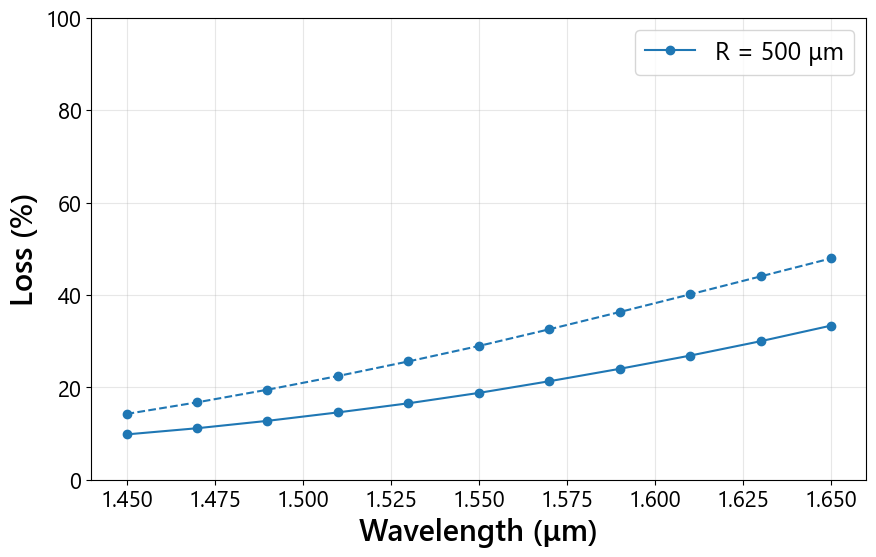

In [8]:
device_name = "P-02_SideStepBend"
working_dir = f"D:\\DATA\\NullingPIC_Gen2_sims\\{device_name}\\"
save_dir = f"{working_dir}{device_name}_scan_BendRadius_Wav\\"
CAD_filename = f"{device_name}.ind"

wav_arr = np.load(f"{save_dir}{device_name}_Wav.npy")
bendRadius_arr = np.load(f"{save_dir}{device_name}_bendRadius.npy")[:1]

# Output plane: use the end of the simulation domain unless you set z_out explicitly
z_out = None  # e.g. z_out = 16002

monitors = np.full((len(bendRadius_arr), len(wav_arr)), np.nan)
Input_length, Output_length = float(rlib.read_symbol(working_dir+CAD_filename, "Input_length")), float(rlib.read_symbol(working_dir+CAD_filename, "Output_length"))
Bend_offset = float(rlib.read_symbol(working_dir+CAD_filename, "Bend_offset"))

losses_expected = []
for i, bendRadius in enumerate(bendRadius_arr):
    bendRadius_str = f"{bendRadius:0.3f}".replace(".", "p")
    L_cm = sbend_lengths(bendRadius, Bend_offset)[0] * 1e-4   # arc length, μm -> cm
    loss_expected = []
    for j, wav in enumerate(wav_arr):
        wav_str = f"{wav:0.3f}".replace(".", "p")
        loss_dB = get_loss(bendRadius, wav) * L_cm
        loss_expected.append((1 - 10**(-loss_dB / 10)) * 100)   # % of power lost

        monitor_filename = f"{save_dir}{device_name}_scan_BendRadius{bendRadius_str}_Wav{wav_str}.mon"
        monitor = rlib.read_monitor(monitor_filename)

        z = np.asarray(monitor.z)
        z_target = z.max() if z_out is None else z_out
        mask = np.isclose(z, z_target)
        monitors[i, j] = monitor.values[mask].flatten()[0]
    losses_expected.append(loss_expected)
losses_expected = np.array(losses_expected)

plt.figure(figsize=(10, 6))
for i, R in enumerate(bendRadius_arr):
    plt.plot(wav_arr, (1 - monitors[i]) * 100, color=f'C{i}', marker='o', label=f"R = {R:.0f} μm")
    plt.plot(wav_arr, losses_expected[i], linestyle='dashed', color=f'C{i}', marker='o')
plt.xlabel('Wavelength (μm)')
plt.ylabel('Loss (%)')
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 100)
plt.show()

Coupling length 278: 17 of 45 runs available
Coupling length 308: 1 of 45 runs available
Coupling length 338: 0 of 45 runs available


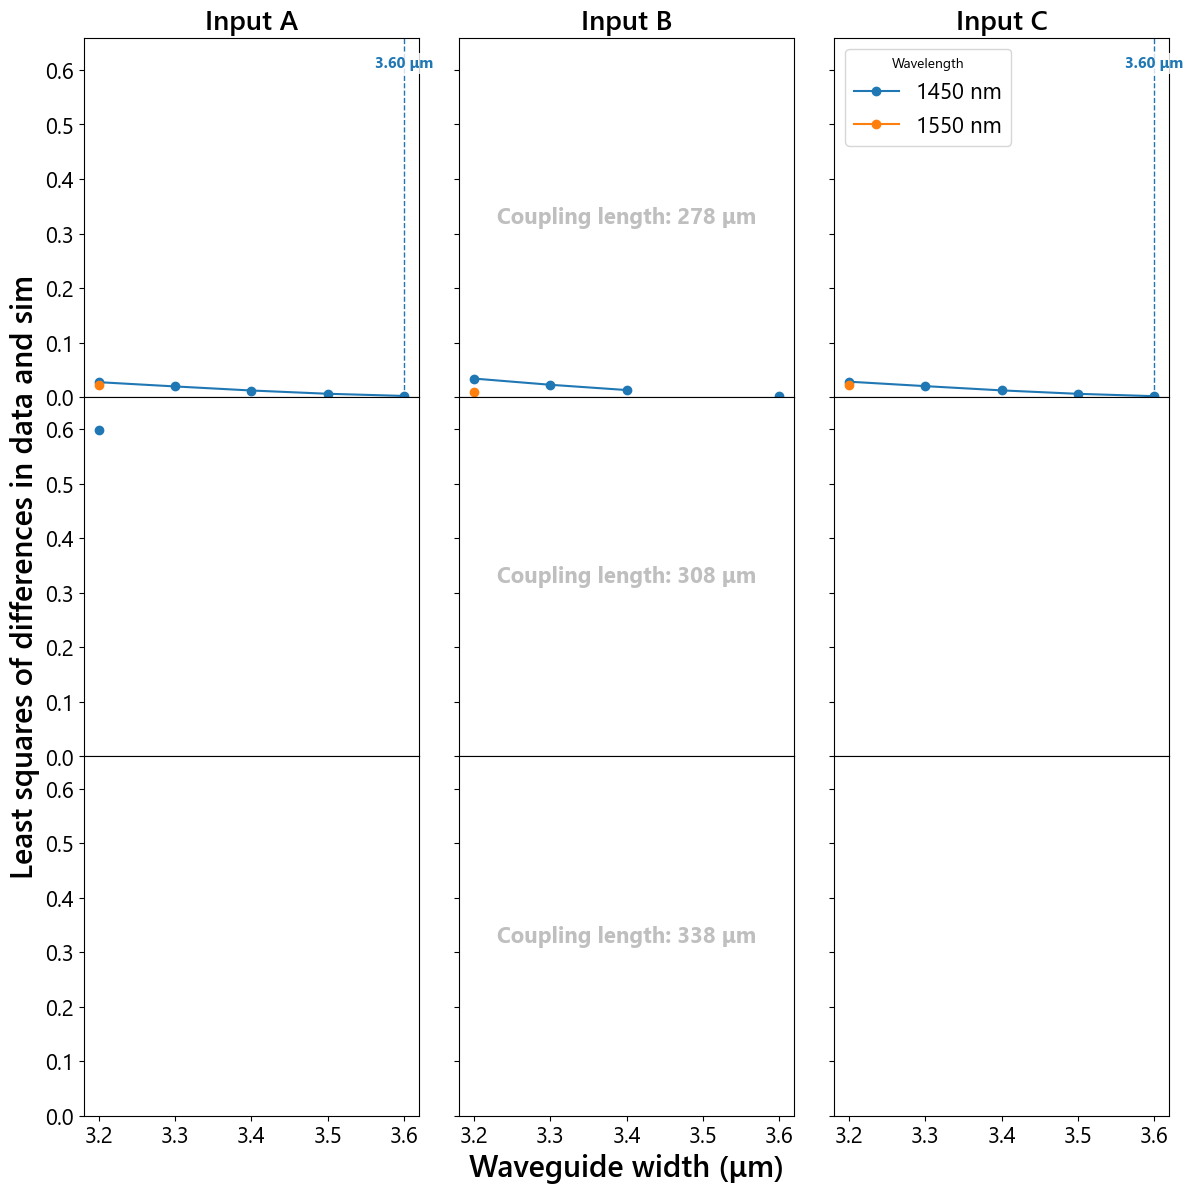


Best width (μm) for each coupling length, input and wavelength ('-' = no minimum found yet in the finished widths)
    L  input     1450     1550     1650
  278      A    3.600        -        -
  278      B        -        -        -
  278      C    3.600        -        -
  308      A        -        -        -
  308      B        -        -        -
  308      C        -        -        -
  338      A        -        -        -
  338      B        -        -        -
  338      C        -        -        -


In [61]:
import matplotlib.pyplot as plt
import numpy as np

import rsoft_lib as rlib

working_dir = "D:\\DATA\\ActivePIC\\Tricoupler\\"
data_dir = f"{working_dir}tricoupler_passive_data\\"                  # measured splitting: Tricoupler_couplingLength{L}_input{A,B,C}.txt
filename_root = "Tricoupler_FiberOneInput"

coupling_lengths = [278, 308, 338]
inputs = ["A", "B", "C"]
target_wavs = [1450, 1550, 1650]                                       # nm; must be among the wavelengths of the scan
widths = np.linspace(3.2, 3.6, 5)                                      # the widths of the scan (the .npy is only saved when a coupling length finishes)


def sim_folder(coupling_length):
    return f"{working_dir}Tricoupler_passive_sim\\{filename_root}_couplingLength{coupling_length}_scan_Wav_Width\\"


def read_sim(coupling_length, input_name, width, wav_um):
    """(fractions of the total power in outputs A, B, C, last z) of one simulation, or None if it has not run."""
    path = (f"{sim_folder(coupling_length)}{filename_root}_couplingLength{coupling_length}_input{input_name}"
            f"_Width{rlib.param_str(width, 2)}_Wav{rlib.param_str(wav_um)}.mon")
    try:
        mon = rlib.read_monitor(path)
    except (OSError, ValueError):
        return None
    power_cols = [i for i, t in enumerate(mon.type) if t == "FILE_POWER"]
    if len(power_cols) != 3:
        raise ValueError(f"Expected 3 power monitors (outputs A, B, C), found the monitor types {mon.type}")
    p = mon.values[-1, power_cols]
    return p / p.sum(), mon.z[-1]


def best_width(w, y):
    """Width at the minimum of the finished points; a parabola through the lowest point and its neighbours refines it.
    A minimum at the end of a scan that is still running is not a minimum yet, so it returns None."""
    ok = np.isfinite(y)
    complete = ok.all()
    w, y = w[ok], y[ok]
    if len(y) < 3:
        return None
    k = int(np.argmin(y))
    if 0 < k < len(y) - 1:
        a, b, _ = np.polyfit(w[k - 1:k + 2], y[k - 1:k + 2], 2)
        if a > 0:
            return -b / (2 * a)
    return w[k] if complete else None


# measured data (read each file once)
data = {(L, name): np.genfromtxt(f"{data_dir}Tricoupler_couplingLength{L}_input{name}.txt", names=True, delimiter=',')
        for L in coupling_lengths for name in inputs}

# simulations that exist so far; a run that stops short in z (still running) is ignored
sims = {}
for L in coupling_lengths:
    found = {}
    for name in inputs:
        for target in target_wavs:
            for i, w in enumerate(widths):
                result = read_sim(L, name, w, target / 1000)
                if result is not None:
                    found[(name, target, i)] = result
    if found:
        z_max = max(z for _, z in found.values())
        found = {k: f for k, (f, z) in found.items() if z > z_max - 1.0}
    sims.update({(L,) + k: f for k, f in found.items()})
    print(f"Coupling length {L}: {len(found)} of {len(inputs) * len(target_wavs) * len(widths)} runs available")

# least squares of the difference in splitting fractions, for every width that has run
lsq = {}
for L in coupling_lengths:
    for name in inputs:
        for target in target_wavs:
            row = data[(L, name)][np.isclose(data[(L, name)]['wav'], target, atol=0.1)]
            measured = np.array([row['outputA'][0], row['outputB'][0], row['outputC'][0]])
            measured = measured / measured.sum()
            lsq[(L, name, target)] = np.array([np.sum((sims[(L, name, target, i)] - measured) ** 2)
                                               if (L, name, target, i) in sims else np.nan for i in range(len(widths))])
if not any(np.isfinite(y).any() for y in lsq.values()):
    raise RuntimeError("No finished simulations found yet.")

# plot
ymax = 1.1 * max(np.nanmax(y) for y in lsq.values() if np.isfinite(y).any())
fig, ax = plt.subplots(3, 3, figsize=(14, 14), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.12, hspace=0)
best = {}
for row_i, L in enumerate(coupling_lengths):
    for col, name in enumerate(inputs):
        for i_wav, target in enumerate(target_wavs):
            y = lsq[(L, name, target)]
            if not np.isfinite(y).any():
                continue
            line, = ax[row_i, col].plot(widths, y, 'o-', color=f'C{i_wav}', label=f'{target} nm')
            w_best = best_width(widths, y)
            best[(L, name, target)] = w_best
            if w_best is not None:                                      # needs a minimum inside the finished widths
                ax[row_i, col].axvline(w_best, linestyle='--', linewidth=1, color=line.get_color())
                ax[row_i, col].text(w_best, 0.95 - 0.09 * i_wav, f'{w_best:.2f} μm', transform=ax[row_i, col].get_xaxis_transform(),
                                    ha='center', va='top', color=line.get_color(), fontsize=11, fontweight='bold',
                                    bbox=dict(facecolor='white', edgecolor='none', alpha=0.8, pad=2))
        ax[row_i, col].set(ylim=(0, ymax))
        ax[row_i, col].set_xticks(widths)
    ax[row_i, 1].text(0.5, 0.5, f'Coupling length: {L} μm', transform=ax[row_i, 1].transAxes, ha='center', va='center',
                      fontsize=16, fontweight='bold', alpha=0.25)
for col, name in enumerate(inputs):
    ax[0, col].set_title(f'Input {name}')
ax[0, 2].legend(fontsize=16, title='Wavelength')
ax[2, 1].set_xlabel('Waveguide width (μm)')
ax[1, 0].set_ylabel('Least squares of differences in data and sim')
plt.show()

print("\nBest width (μm) for each coupling length, input and wavelength ('-' = no minimum found yet in the finished widths)")
print(f"{'L':>5s}{'input':>7s}" + "".join(f"{t:>9d}" for t in target_wavs))
for L in coupling_lengths:
    for name in inputs:
        print(f"{L:5d}{name:>7s}" + "".join(f"{best[(L, name, t)]:9.3f}" if best.get((L, name, t)) is not None else f"{'-':>9s}" for t in target_wavs))